In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path

In [2]:
import os

# dataset path
base_dir = r"C:\Users\Kavya\OneDrive\Desktop\eai2\dataset"

# train and test folders 
train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")

# paths exists or not
print("Train directory:", os.path.exists(train_dir))
print("Test directory:", os.path.exists(test_dir))

# class names 
if os.path.exists(train_dir):
    print("\nClasses in Training set:", os.listdir(train_dir))
if os.path.exists(test_dir):
    print("Classes in Test set:", os.listdir(test_dir))

Train directory: True
Test directory: True

Classes in Training set: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Classes in Test set: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Image parameters
IMG_SIZE = (224, 224)  
BATCH_SIZE = 32

# Data augmentation 
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2 
)

# test data rescaling
test_datagen = ImageDataGenerator(rescale=1./255)

# Load training data
train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

# Load validation data
val_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

# Load test data
test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)


Found 8723 images belonging to 6 classes.
Found 2178 images belonging to 6 classes.
Found 2698 images belonging to 6 classes.


In [5]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

# Load MobileNetV2 base model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze base layers
for layer in base_model.layers:
    layer.trainable = False

# Build model
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(6, activation='softmax')  # 6 classes
])

# Compile model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# summary
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Early stopping and model checkpoint setup
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True, verbose=1)

# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    callbacks=[early_stop, checkpoint]
)


C:\Users\Kavya\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 803ms/step - accuracy: 0.4638 - loss: 1.4260
Epoch 1: val_accuracy improved from None to 0.93297, saving model to best_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 277s 1s/step - accuracy: 0.6514 - loss: 0.9458 - val_accuracy: 0.9330 - val_loss: 0.2580
Epoch 2/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - accuracy: 0.8551 - loss: 0.4067
Epoch 2: val_accuracy improved from 0.93297 to 0.94995, saving model to best_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 141s 517ms/step - accuracy: 0.8708 - loss: 0.3718 - val_accuracy: 0.9500 - val_loss: 0.1614
Epoch 3/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step - accuracy: 0.8987 - loss: 0.2817
Epoch 3: val_accuracy improved from 0.94995 to 0.96281, saving model to best_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 142s 519ms/step - accuracy: 0.9054 - loss: 0.2646 - val_accuracy: 0.9628 - val_loss: 0.1196
Epoch 4/15
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.9216 - loss: 0.2286
Epoch 4: val_accuracy im

In [7]:
# best saved model
from tensorflow.keras.models import load_model
model = load_model('best_model.keras')

# Evaluate on test data
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


85/85 ━━━━━━━━━━━━━━━━━━━━ 49s 566ms/step - accuracy: 0.9770 - loss: 0.0644
Test Accuracy: 97.70%
Test Loss: 0.0644


In [8]:
import matplotlib.pyplot as plt

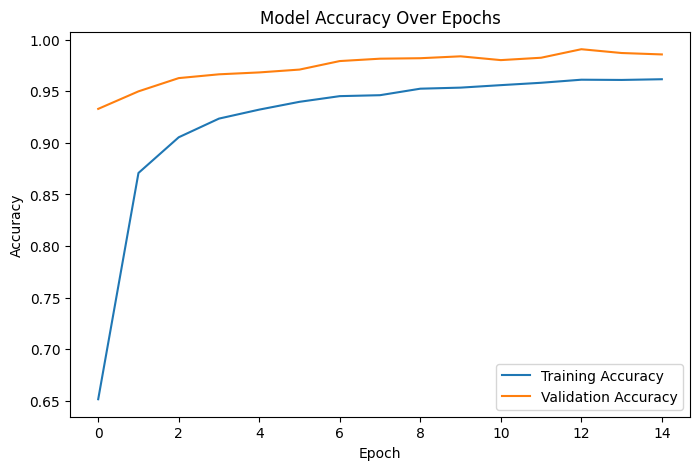

In [9]:
# accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

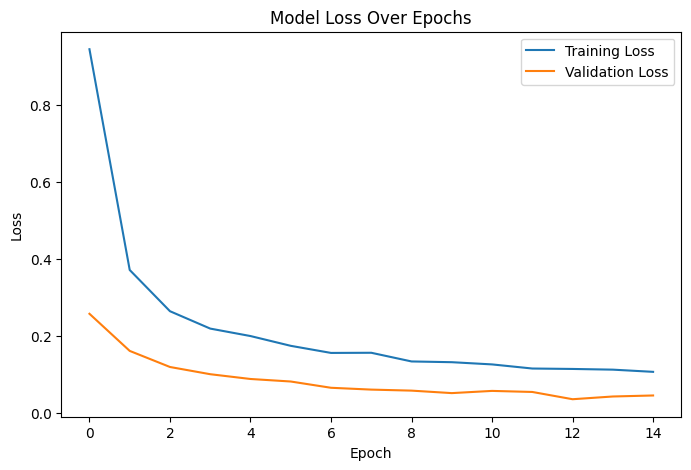

In [10]:
# loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Loading model...
Model loaded from: C:\Users\Kavya\OneDrive\Desktop\eai2\best_model.keras
Classes: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']

Random image: rotated_by_60_Screen Shot 2018-06-08 at 2.25.04 PM.png (True class: rottenapples)


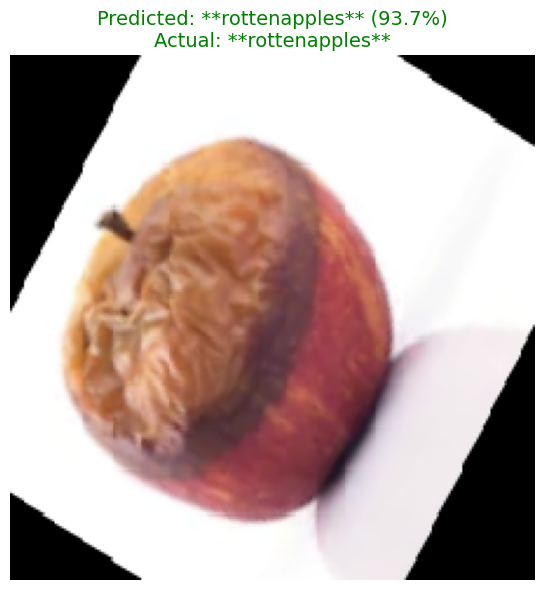

In [ ]:
MODEL_PATH  = r"C:\Users\Kavya\OneDrive\Desktop\eai2\best_model.keras"   
TEST_FOLDER = r"C:\Users\Kavya\OneDrive\Desktop\eai2\dataset\test"      

import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

print("Loading model...")
model = load_model(MODEL_PATH)                    
print(f"Model loaded from: {MODEL_PATH}")

class_names = sorted(os.listdir(TEST_FOLDER))      
class_indices = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in class_indices.items()}

print("Classes:", class_names)

chosen_class = random.choice(class_names)
class_folder = os.path.join(TEST_FOLDER, chosen_class)
chosen_img   = random.choice(os.listdir(class_folder))
img_path     = os.path.join(class_folder, chosen_img)

print(f"\nRandom image: {chosen_img} (True class: {chosen_class})")

img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img) / 255.0          
img_array = np.expand_dims(img_array, axis=0)        

prediction = model.predict(img_array, verbose=0)     
pred_probs = prediction.flatten()
pred_idx   = np.argmax(pred_probs)
pred_label = idx_to_class[pred_idx]
confidence = pred_probs[pred_idx]

plt.figure(figsize=(6, 6))
plt.imshow(img)
title_color = "green" if pred_label == chosen_class else "red"
plt.title(
    f"Predicted: **{pred_label}** ({confidence:.1%})\n"
    f"Actual: **{chosen_class}**",
    fontsize=14, color=title_color
)
plt.axis("off")
plt.tight_layout()
plt.show()

85/85 ━━━━━━━━━━━━━━━━━━━━ 23s 256ms/step
Classification Report:
               precision    recall  f1-score   support

  freshapples       0.97      0.98      0.97       395
  freshbanana       1.00      1.00      1.00       381
 freshoranges       0.99      0.95      0.97       388
 rottenapples       0.96      0.98      0.97       601
 rottenbanana       1.00      1.00      1.00       530
rottenoranges       0.95      0.95      0.95       403

     accuracy                           0.98      2698
    macro avg       0.98      0.98      0.98      2698
 weighted avg       0.98      0.98      0.98      2698



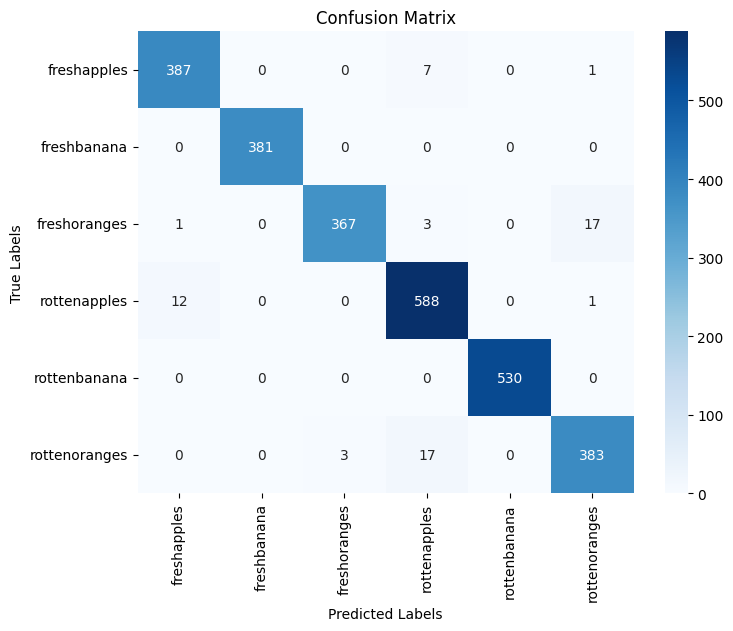

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# labels and predictions
Y_pred = model.predict(test_gen)
y_pred = np.argmax(Y_pred, axis=1)

# Classification report
print("Classification Report:")
print(classification_report(test_gen.classes, y_pred, target_names=list(test_gen.class_indices.keys())))

# Confusion matrix
cm = confusion_matrix(test_gen.classes, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=list(test_gen.class_indices.keys()),
            yticklabels=list(test_gen.class_indices.keys()))
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()


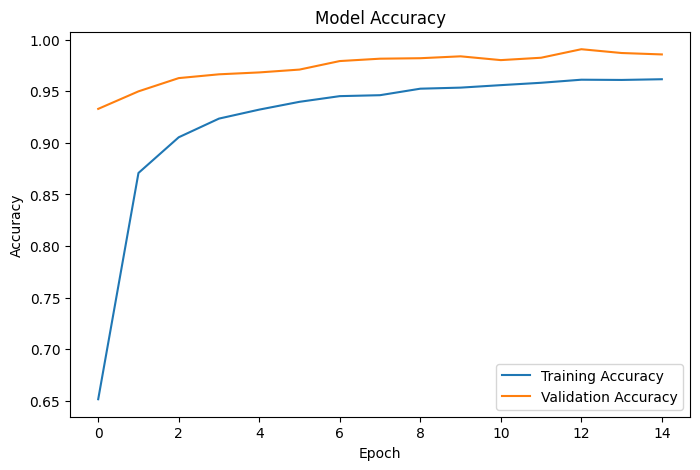

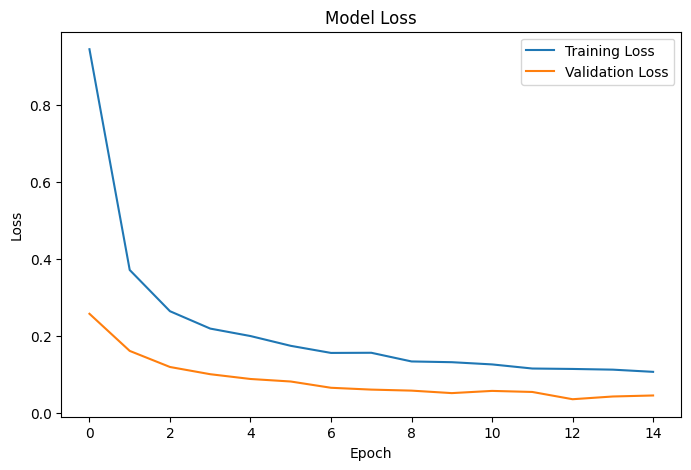

In [13]:
# training vs validation accuracy
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# training vs validation loss
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
# Save the best model 
model.save("fruit_quality_model.h5")
print("Model saved as 'fruit_quality_model.h5'")

Model saved as 'fruit_quality_model.h5'


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


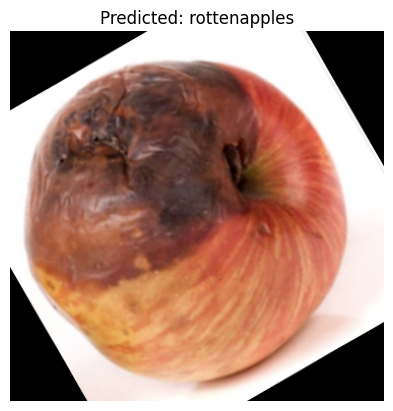

In [15]:
# test image
img_path = random.choice(test_gen.filepaths)
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
pred = model.predict(img_array)
pred_class = np.argmax(pred, axis=1)[0]
label_map = {v: k for k, v in train_gen.class_indices.items()}
pred_label = label_map[pred_class]

# Display
plt.imshow(image.load_img(img_path))
plt.title(f"Predicted: {pred_label}")
plt.axis('off')
plt.show()

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
import os

In [5]:
# Create YOLO folder structure
os.makedirs('yolo_dataset/train/images', exist_ok=True)
os.makedirs('yolo_dataset/train/labels', exist_ok=True)
os.makedirs('yolo_dataset/val/images', exist_ok=True)
os.makedirs('yolo_dataset/val/labels', exist_ok=True)


In [7]:
import os
import shutil
from PIL import Image
import glob

# Classes
classes = [
    "freshapples", "freshbanana", "freshoranges",
    "rottenapples", "rottenbanana", "rottenoranges"
]

class_to_id = {c: i for i, c in enumerate(classes)}

def prepare_yolo_data(split):
    base_dir = f"dataset/{split}"
    dest_img = f"yolo_dataset/{'train' if split=='train' else 'val'}/images"
    dest_lbl = f"yolo_dataset/{'train' if split=='train' else 'val'}/labels"

    for c in classes:
        img_paths = glob.glob(f"{base_dir}/{c}/*")
        for img_path in img_paths:
            img_name = os.path.basename(img_path)
            shutil.copy(img_path, f"{dest_img}/{img_name}")
            # YOLO label format: class x_center y_center width height (full image)
            label_path = f"{dest_lbl}/{os.path.splitext(img_name)[0]}.txt"
            with open(label_path, "w") as f:
                f.write(f"{class_to_id[c]} 0.5 0.5 1.0 1.0\n")

prepare_yolo_data("train")
prepare_yolo_data("test")
print("Dataset prepared for YOLO format.")


✅ Dataset prepared for YOLO format.


In [ ]:
data_yaml = """
train: yolo_dataset/train/images
val: yolo_dataset/val/images

nc: 6
names: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
"""

with open("data.yaml", "w") as f:
    f.write(data_yaml)

print(" data.yaml created")


✅ data.yaml created


In [9]:
model = YOLO("yolov8n.pt")  
model.train(
    data="data.yaml",
    epochs=30,
    imgsz=640,
    batch=8,
    name="fruit_yolo_model",
)


New https://pypi.org/project/ultralytics/8.3.223 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.221  Python-3.13.2 torch-2.9.0+cpu CPU (AMD Ryzen 7 7735HS with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=fruit_yolo_model, nbs=64, nms=False, opset=N

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001C2881FC130>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
 

In [10]:
results = model.val()

Ultralytics 8.3.221  Python-3.13.2 torch-2.9.0+cpu CPU (AMD Ryzen 7 7735HS with Radeon Graphics)
Model summary (fused): 72 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 834.8464.8 MB/s, size: 131.6 KB)
val: Scanning C:\Users\Kavya\OneDrive\Desktop\eai2\yolo_dataset\val\labels.cache... 2698 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2698/2698 3.8Mit/s 0.0s0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 169/169 1.2it/s 2:170.7ss
                   all       2698       2698      0.999          1      0.995      0.995
           freshapples        395        395          1          1      0.995      0.995
           freshbanana        381        381          1          1      0.995      0.995
          freshoranges        388        388          1          1      0.995      0.995
          rottenapples        601        601          1      0.999      0.995      0.

In [ ]:
from ultralytics import YOLO
model = YOLO("runs/detect/fruit_yolo_model/weights/best.pt")

# Export to ONNX
success = model.export(format="onnx")
print("Export success:", success)
print("ONNX file saved to:")
print("   runs/detect/fruit_yolo_model/weights/best.onnx")

Ultralytics 8.3.221  Python-3.13.2 torch-2.9.0+cpu CPU (AMD Ryzen 7 7735HS with Radeon Graphics)
Model summary (fused): 72 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from 'runs\detect\fruit_yolo_model\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 10, 8400) (5.9 MB)

ONNX: starting export with onnx 1.19.1 opset 22...
ONNX: slimming with onnxslim 0.1.72...
ONNX: export success  2.3s, saved as 'runs\detect\fruit_yolo_model\weights\best.onnx' (11.7 MB)

Export complete (2.6s)
Results saved to C:\Users\Kavya\OneDrive\Desktop\eai2\runs\detect\fruit_yolo_model\weights
Predict:         yolo predict task=detect model=runs\detect\fruit_yolo_model\weights\best.onnx imgsz=640  
Validate:        yolo val task=detect model=runs\detect\fruit_yolo_model\weights\best.onnx imgsz=640 data=data.yaml  
Visualize:       https://netron.app
Export success: runs\detect\fruit_yolo_model\weights\best.onnx
ONNX file saved to:
   runs/detect/fruit_yol

Loading YOLOv8 model …
Model loaded: runs/detect/fruit_yolo_model/weights/best.pt
Running inference on: C:\Users\Kavya\OneDrive\Desktop\eai2\dataset\test\rottenoranges\rotated_by_15_Screen Shot 2018-06-12 at 11.18.46 PM.png
Results saved to C:\Users\Kavya\OneDrive\Desktop\eai2\runs\detect\test_inference

           DETECTION SUMMARY
Total fruits detected: 1
   • rottenoranges: 1
Saved image not found – drawing manually …


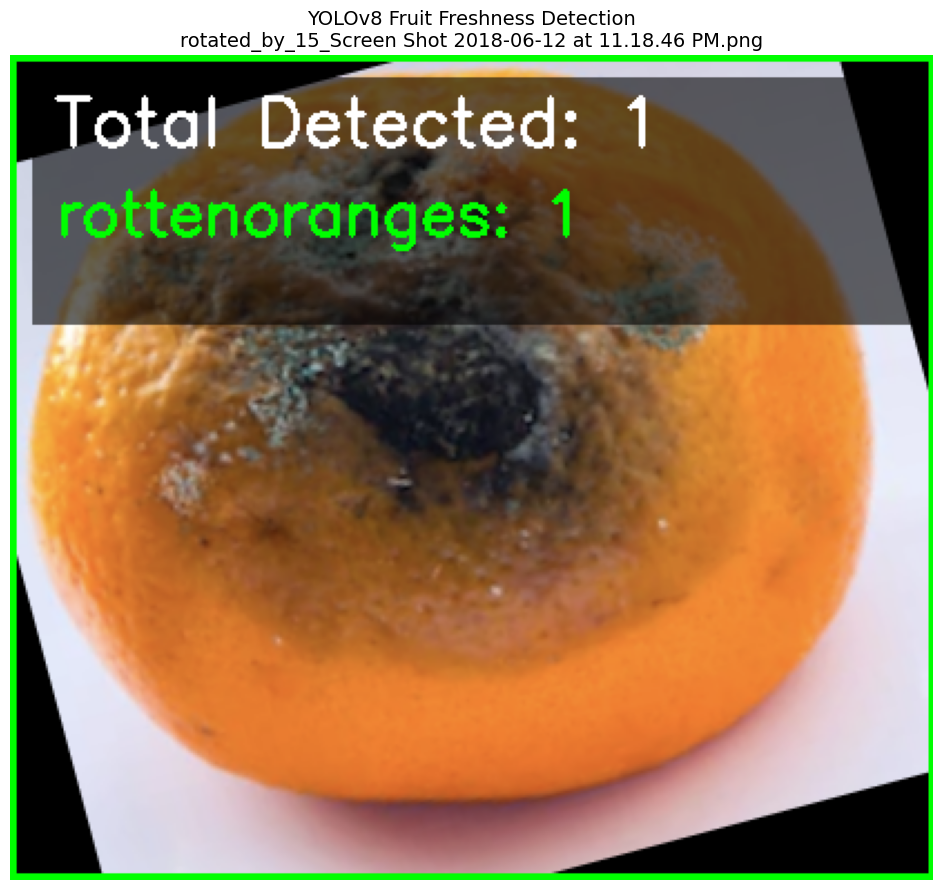


Result image: drawn in-memory


In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os
from collections import Counter

MODEL_PATH = "runs/detect/fruit_yolo_model/weights/best.pt"
IMAGE_PATH = r"C:\Users\Kavya\OneDrive\Desktop\eai2\dataset\test\rottenoranges\rotated_by_15_Screen Shot 2018-06-12 at 11.18.46 PM.png"

CONFIDENCE  = 0.5
SAVE_OUTPUT = True
PROJECT_DIR = "runs/detect"
RUN_NAME    = "test_inference"

print("Loading YOLOv8 model …")
model = YOLO(MODEL_PATH)
print(f"Model loaded: {MODEL_PATH}")

print(f"Running inference on: {IMAGE_PATH}")
results = model.predict(
    source=IMAGE_PATH,
    conf=CONFIDENCE,
    save=SAVE_OUTPUT,
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,
    verbose=False
)[0]

detections = []
if results.boxes is not None and len(results.boxes) > 0:
    for box in results.boxes:
        cls_id = int(box.cls.item())
        conf   = box.conf.item()
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        label  = model.names[cls_id]
        detections.append({
            'label': label,
            'conf': conf,
            'box': (x1, y1, x2, y2)
        })

# Count per class
count_summary = Counter(d['label'] for d in detections)
total_count = len(detections)

print("\n" + "="*50)
print("           DETECTION SUMMARY")
print("="*50)
if total_count == 0:
    print("No fruits detected above confidence threshold.")
else:
    print(f"Total fruits detected: {total_count}")
    for label, count in count_summary.most_common():
        print(f"   • {label}: {count}")
print("="*50)

saved_dir = os.path.join(PROJECT_DIR, RUN_NAME)
saved_img_path = os.path.join(saved_dir, os.path.basename(IMAGE_PATH))

if os.path.exists(saved_img_path):
    img = cv2.imread(saved_img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
else:
    print("Saved image not found – drawing manually …")
    img = cv2.imread(IMAGE_PATH)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # Draw boxes
    for d in detections:
        x1, y1, x2, y2 = d['box']
        label = d['label']
        conf = d['conf']
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img, f"{label} {conf:.2f}", (x1, y1-10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

h, w = img.shape[:2]
overlay = img.copy()
cv2.rectangle(overlay, (10, 10), (w-10, 120), (0, 0, 0), -1)  
alpha = 0.6
cv2.addWeighted(overlay, alpha, img, 1 - alpha, 0, img)

y = 40
cv2.putText(img, f"Total Detected: {total_count}", (20, y),
            cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
y += 40
for label, count in count_summary.most_common():
    cv2.putText(img, f"{label}: {count}", (20, y),
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
    y += 30

plt.figure(figsize=(12, 9))
plt.imshow(img)
plt.title(f"YOLOv8 Fruit Freshness Detection\n{os.path.basename(IMAGE_PATH)}", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

print(f"\nResult image: {saved_img_path if os.path.exists(saved_img_path) else 'drawn in-memory'}")